# 第 04 课｜金融市场基础速览

> **数据身份**：固定随机种子生成的模拟教学数据，不是真实证券行情。  
> **环境**：`pkm-quant` · Python 3.11 · 默认离线运行。  
> **课程原始材料**：`04_youtube-mjogM5-bYd0/index.html`  
> **所属模块**：P1-M1 · 研究问题与市场假设

## 本节量化问题

不同资产的价格、交易规则和收益能否直接放在同一张图比较？

## 准确定义与策略报告位置

资产比较必须统一币种、时点、复权、收益口径和起始基准；价格水平本身通常不可直接横向比较。

- **核心关系**：归一化净值：I_t = P_t / P_0。只有统一起点后，价格路径才可比较。
- **写入报告**：资产范围、市场规则和比较基准
- **P2 衔接**：P2 第 34–35、43–44 课：行情表、时间索引和数据接口。


## 运行环境与数据契约

先确认项目、数据目录和数据身份。后续联网数据源必须通过适配层进入，不能改变本 Notebook 的研究计算口径。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "fixtures").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "fixtures"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_SEED = 365
print("项目:", ROOT)
print("数据:", DATA_DIR)
print("数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情")


项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations
数据: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p1-quant-foundations/data/fixtures
数据身份: 固定随机种子生成的模拟教学数据，不是真实证券行情


## 从价格表得到可比净值

先查看长表字段，再把 `date × symbol` 重排为价格矩阵。归一化只改变比较基准，不改变单期收益。

In [2]:
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
print("原始长表字段:", daily.columns.tolist())
display(daily.head(8))

close = daily.pivot(index="date", columns="symbol", values="adj_close").sort_index()
normalized = close.divide(close.iloc[0], axis="columns")

assert np.allclose(normalized.iloc[0], 1.0)
display(normalized.head())

原始长表字段: ['date', 'symbol', 'adj_close', 'raw_close', 'currency', 'frequency']


,date,symbol,adj_close,raw_close,currency,frequency
0,2023-01-03,SIM_MARKET,99.777453,99.777453,CNY,1d
1,2023-01-03,SIM_VALUE,42.315093,42.315093,CNY,1d
2,2023-01-03,SIM_GROWTH,34.824858,34.824858,CNY,1d
3,2023-01-03,SIM_DEFENSIVE,27.883400,27.883400,CNY,1d
4,2023-01-03,SIM_COMMODITY,54.420881,54.420881,CNY,1d
5,2023-01-03,SIM_BOND,97.849971,97.849971,CNY,1d
6,2023-01-04,SIM_MARKET,100.862394,100.862394,CNY,1d
7,2023-01-04,SIM_VALUE,42.643685,42.643685,CNY,1d


symbol,SIM_BOND,SIM_COMMODITY,SIM_DEFENSIVE,SIM_GROWTH,SIM_MARKET,SIM_VALUE
date,,,,,,
2023-01-03,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2023-01-04,1.001210,1.005793,1.004949,1.004617,1.010874,1.007765
2023-01-05,1.001900,1.000045,0.998477,0.997274,1.011232,0.998560
2023-01-06,1.002128,1.006558,0.997421,0.993295,0.997785,0.988909
2023-01-09,1.002766,1.000296,0.993873,0.989379,0.992508,0.992837


## 比较资产路径

`axis='columns'` 表示每一列除以该列自己的首日价格。图中比较的是模拟资产的相对路径，不是价格高低。

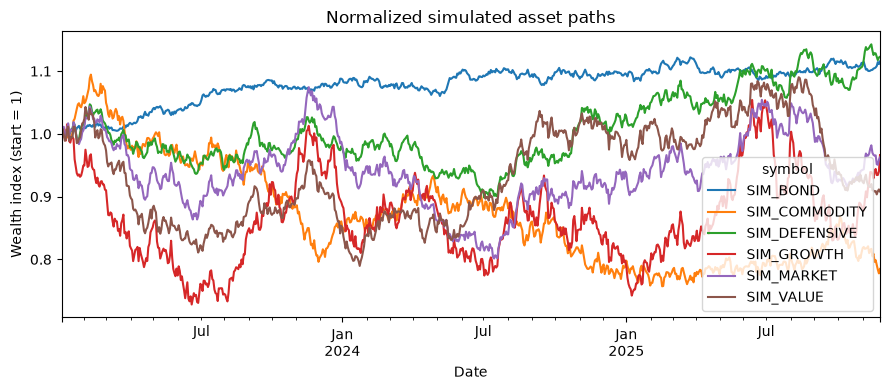

In [3]:
ax = normalized.plot(figsize=(9, 4), title="Normalized simulated asset paths")
ax.set_ylabel("Wealth index (start = 1)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

## 方法边界与阶段验收

教学快照不代表可交易数据，跨市场还需处理时区、节假日、汇率和合约换月。

完成本课后应能：

1. 不看课程材料准确解释核心概念和公式符号；
2. 用小样本手工核对 Notebook 的关键结果；
3. 说明结果能支持什么判断、不能支持什么判断；
4. 指出它在策略报告中的位置，以及仍缺少的数据、成本或稳健性证据。
